In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.insert(1, '../')
sys.path.insert(1, '../RandomForest')
from MyLovelyFunctions import *
from PrepDataFunctions import *

### Prepare data

In [4]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['mean_sm_2_before_event'].notna()]
df =df[df['start_year']>1990]

### Add season variables

In [10]:
# season_map = {12:'DJF',1:'DJF',2:'DJF', 3:'MAM',4:'MAM',5:'MAM',
#               6:'JJA',7:'JJA',8:'JJA', 9:'SON',10:'SON',11:'SON'}
# df['season'] = df['start_month'].map(season_map)

### Subset events by length

In [11]:
short_events = df[df['length_of_active_rain']<10].copy()
med_events = df[(df['length_of_active_rain']>10) & (df['length_of_active_rain'] < 50)].copy()
long_events = df[(df['length_of_active_rain']>50) & (df['length_of_active_rain'] < 80)].copy()

### Create annual summaries for several variables

In [12]:
annual_mean_sm = (df.groupby("start_year", observed=True)["mean_sm_2_before_event"].mean())
annual_mean_fu = (df.groupby("start_year", observed=True)["fu_at_peak_new"].mean())

### Create plots split by season

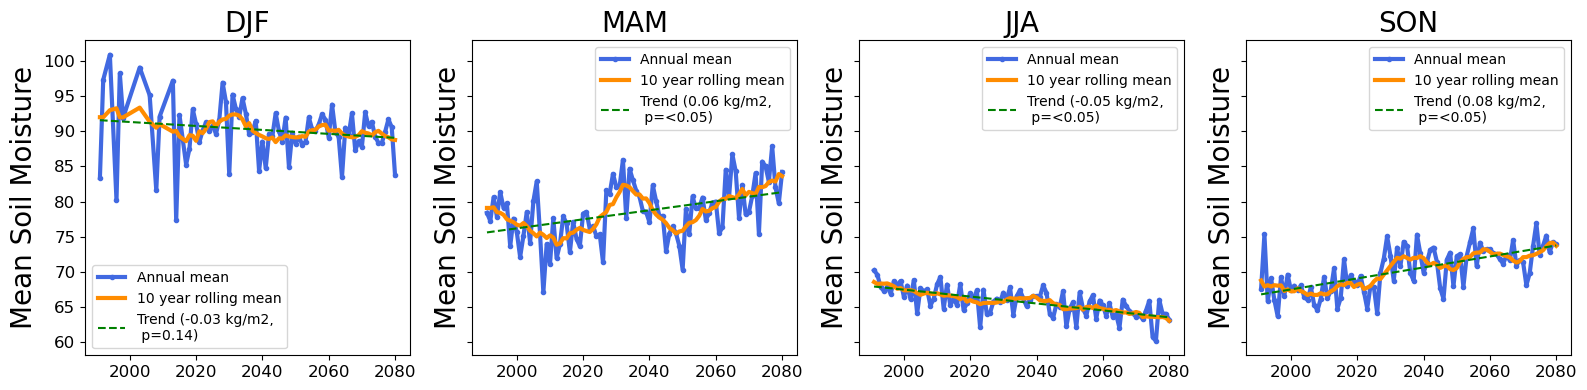

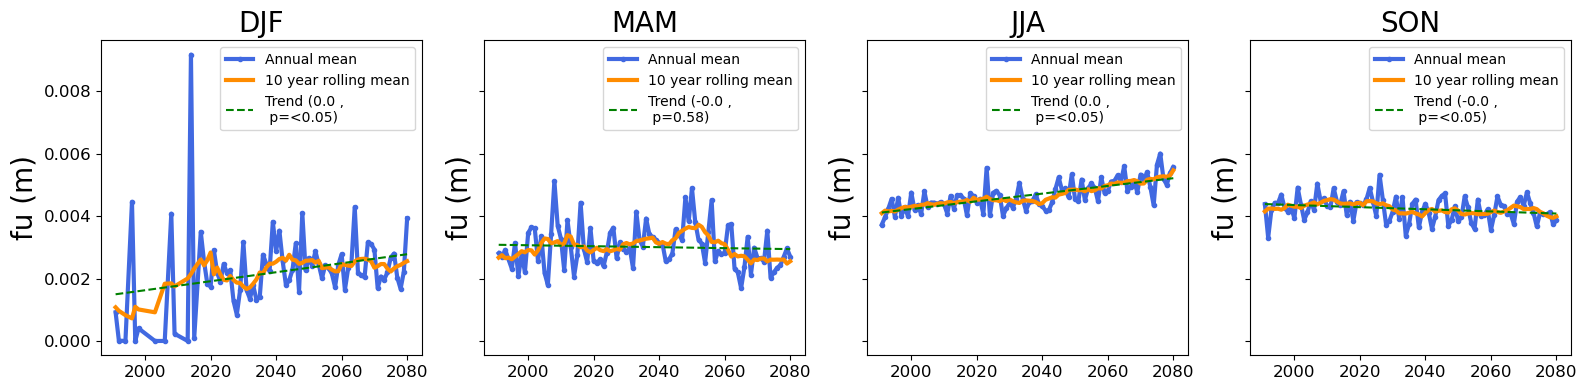

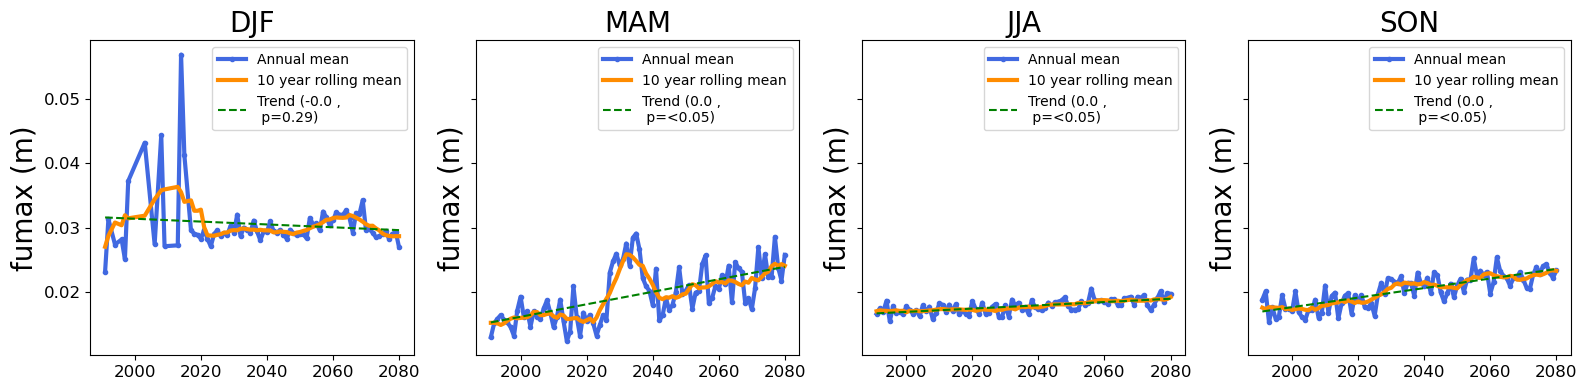

In [8]:
# fig, axs = plt.subplots(nrows = 2, figsize=(10, 7), sharex=False)

# make_subplot(axs[0], annual_mean_sm, "Num cells", "Annual mean per-event spatial extent", 2, "cells")
# make_subplot(axs[1], annual_mean_fu, "Num cells", "Annual mean per-event spatial extent", 2, "cells")

# plt.tight_layout()


fig, axes = plt.subplots(1, 4, figsize=(16,4), sharey=True)
for ax, season in zip(axes, ['DJF','MAM','JJA','SON']):
    sub = df[df['season'] == season]
    annual_mean_sm = (sub.groupby("start_year", observed=True)["mean_sm_2_before_event"].mean())
    make_subplot(ax, annual_mean_sm, "Mean Soil Moisture", f"{season}", 2, "kg/m2", True)
# ax.legend()
fig.tight_layout()

fig, axes = plt.subplots(1, 4, figsize=(16,4), sharey=True)
for ax, season in zip(axes, ['DJF','MAM','JJA','SON']):
    sub = df[df['season'] == season]
    annual_mean_fu = (sub.groupby("start_year", observed=True)["fu_at_peak_new"].mean())
    make_subplot(ax, annual_mean_fu, "fu (m)", f"{season}", 2, "", True)
# ax.legend()
fig.tight_layout()

fig, axes = plt.subplots(1, 4, figsize=(16,4), sharey=True)
for ax, season in zip(axes, ['DJF','MAM','JJA','SON']):
    sub = df[df['season'] == season]
    annual_mean_fumax = (sub.groupby("start_year", observed=True)["fumax_at_peak"].mean())
    make_subplot(ax, annual_mean_fumax, "fumax (m)", f"{season}", 2, "", True)
# ax.legend()
fig.tight_layout()
